**Import libraries**

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Load the dataset**

In [59]:
df = pd.read_csv(
    "../data/raw/diabetic_data.csv",
    na_values=["?"]
)

print("Dataset loaded successfully!")

# Why na_values=["?"] ?
# In Notebook 1, we discovered that the dataset uses ? for missing values.
# This tells Pandas to treat ? as a missing value.

C:\Users\praso\AppData\Local\Temp\ipykernel_13372\814201969.py:1: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Dataset loaded successfully!


**Dataset Size**

In [60]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 101766
Number of columns: 50


**First 5 rows of the dataset**

In [61]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


**Check missing values**

In [62]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

race                  2273
weight               98569
payer_code           40256
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423
max_glu_serum        96420
A1Cresult            84748
dtype: int64


**Show missing-value percentages**

In [63]:
missing_percentage = (
    df.isnull().mean() * 100
).round(2)

missing_percentage = missing_percentage[
    missing_percentage > 0
].sort_values(ascending=False)

missing_percentage

# I calculated the percentage of missing values so that I could understand the severity of the missing-data 
# problem in each column.

weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

**Visualize missing values**

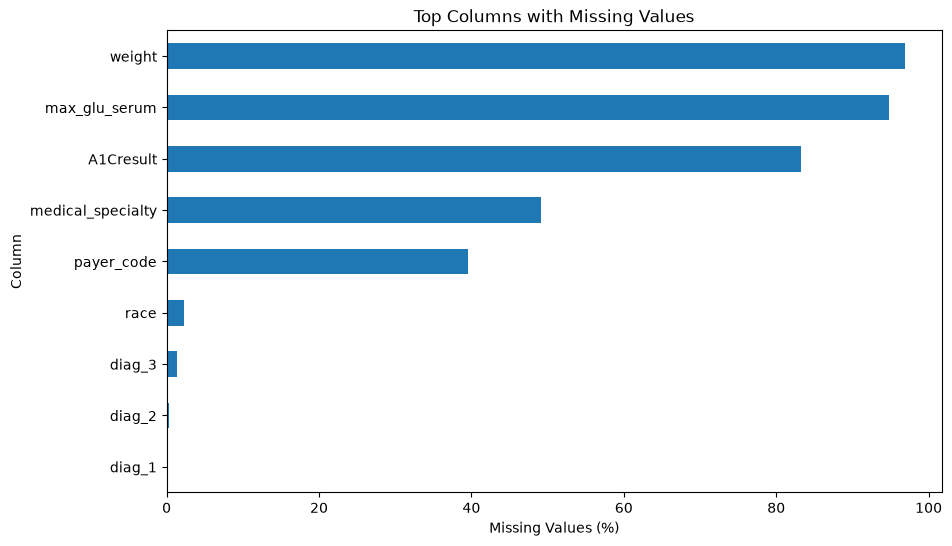

In [64]:
plt.figure(figsize=(10, 6))

missing_percentage.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top Columns with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")

plt.show()

**Create the target variable**

In [65]:
df["readmitted_30_days"] = (
    df["readmitted"] == "<30"
).astype(int)


# 1 = Readmitted within 30 days
# 0 = Not readmitted within 30 days

**Check the new target**

In [66]:
df[
    ["readmitted", "readmitted_30_days"]
].head(15)

# I converted the original three-category readmission variable into a binary target because my machine learning 
# problem is to predict whether a patient will be readmitted within 30 days.

,readmitted,readmitted_30_days
0,NO,0
1,>30,0
2,NO,0
3,NO,0
4,NO,0
5,>30,0
6,NO,0
7,>30,0
8,NO,0
9,NO,0


**Check target distribution**

In [67]:
print(
    df["readmitted_30_days"].value_counts()
)

readmitted_30_days
0    90409
1    11357
Name: count, dtype: int64


In [68]:
# check the percentage
print(
    df["readmitted_30_days"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

readmitted_30_days
0    88.84
1    11.16
Name: proportion, dtype: float64


**Visualize the target**

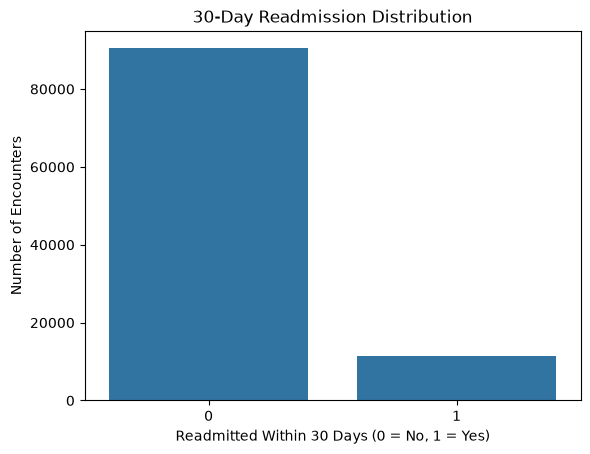

In [69]:
sns.countplot(
    data=df,
    x="readmitted_30_days"
)

plt.title("30-Day Readmission Distribution")
plt.xlabel("Readmitted Within 30 Days (0 = No, 1 = Yes)")
plt.ylabel("Number of Encounters")

plt.show()

**Check duplicate encounters**

In [70]:
print(
    "Duplicate encounter IDs:",
    df["encounter_id"].duplicated().sum()
)

Duplicate encounter IDs: 0


**Check patients and encounters**

In [71]:
# We found in Notebook 1 that one patient can have multiple encounters.
print(
    "Total encounters:",
    len(df)
)

print(
    "Unique patients:",
    df["patient_nbr"].nunique()
)

# I found that the dataset contains multiple encounters for some patients. This is important because later 
# I need to make sure the same patient does not appear in both the training and testing datasets.

Total encounters: 101766
Unique patients: 71518


**Explore age and readmission**

In [72]:
age_readmission = (
    df.groupby("age")["readmitted_30_days"]
    .mean()
    .mul(100)
)

# # Make the age groups easier to read
# age_readmission.index = [
#     str(age_group).replace("[", "").replace(")", "")
#     for age_group in age_readmission.index
# ]

age_readmission

age
[0-10)       1.863354
[10-20)      5.788712
[20-30)     14.242607
[30-40)     11.231788
[40-50)     10.604027
[50-60)      9.666203
[60-70)     11.128408
[70-80)     11.773055
[80-90)     12.083503
[90-100)    11.099177
Name: readmitted_30_days, dtype: float64

**[ means including the first number, while ) means excluding the last number.**

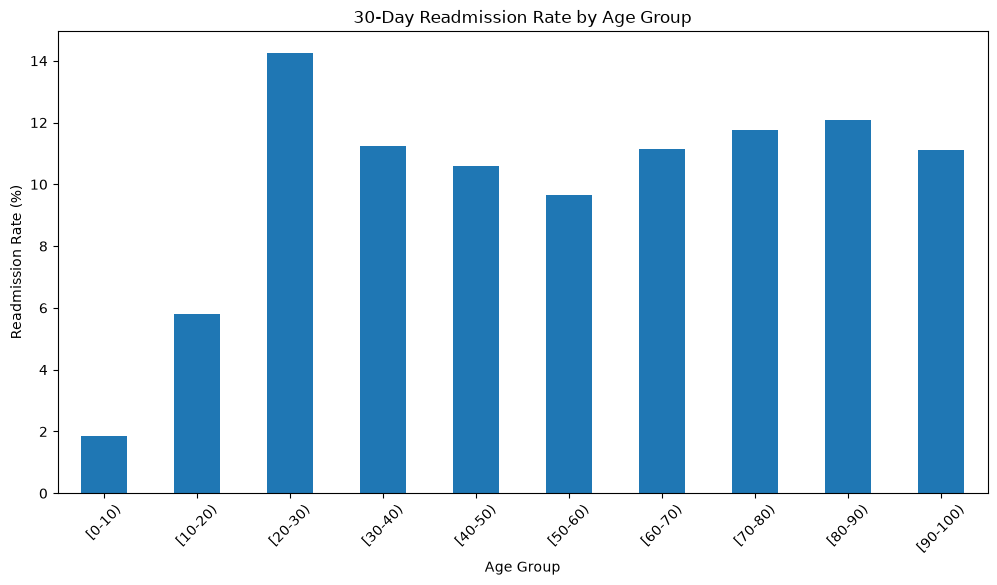

In [73]:
# Visualize the 30-day readmission rate by age group
plt.figure(figsize=(12, 6))

age_readmission.plot(kind="bar")

plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")

plt.xticks(rotation=45)

plt.show()

**Explore hospital stay**

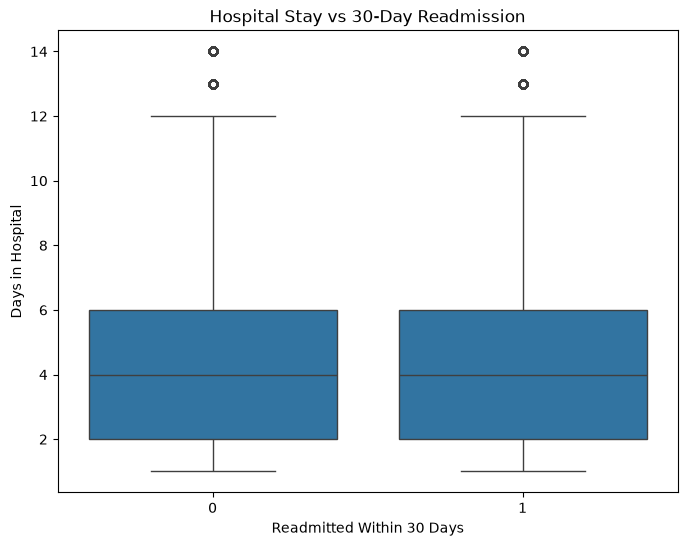

In [74]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="readmitted_30_days",
    y="time_in_hospital"
)

plt.title("Hospital Stay vs 30-Day Readmission")
plt.xlabel("Readmitted Within 30 Days")
plt.ylabel("Days in Hospital")

plt.show()

**Explore previous inpatient visits**

In [75]:
inpatient_rate = (
    df.groupby("number_inpatient")[
        "readmitted_30_days"
    ]
    .mean()
    .mul(100)
)

inpatient_rate.head(10)

# I explored previous inpatient visits because previous healthcare utilization may contain useful information 
# for predicting future readmission.

number_inpatient
0     8.437084
1    12.924543
2    17.433254
3    20.287306
4    23.612824
5    31.403941
6    34.583333
7    35.447761
8    44.370861
9    42.342342
Name: readmitted_30_days, dtype: float64

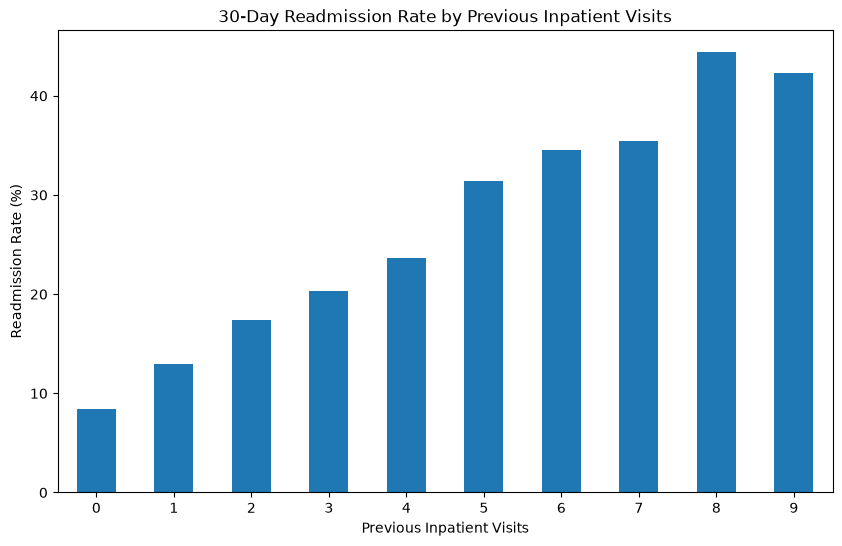

In [76]:
# Visualize the 30-day readmission rate by previous inpatient visits
plt.figure(figsize=(10, 6))

inpatient_rate.head(10).plot(
    kind="bar"
)

plt.title(
    "30-Day Readmission Rate by Previous Inpatient Visits"
)

plt.xlabel("Previous Inpatient Visits")
plt.ylabel("Readmission Rate (%)")

plt.xticks(rotation=0)

plt.show()

**Explore diabetes medication**

In [77]:
medication_rate = (
    df.groupby("diabetesMed")[
        "readmitted_30_days"
    ]
    .mean()
    .mul(100)
)

medication_rate

diabetesMed
No      9.597060
Yes    11.626661
Name: readmitted_30_days, dtype: float64

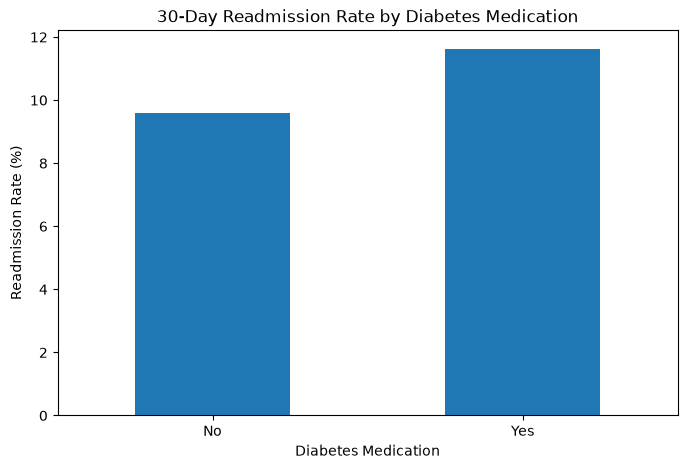

In [78]:
# Visualize the 30-day readmission rate by diabetes medication
plt.figure(figsize=(8, 5))

medication_rate.plot(
    kind="bar"
)

plt.title(
    "30-Day Readmission Rate by Diabetes Medication"
)

plt.xlabel("Diabetes Medication")
plt.ylabel("Readmission Rate (%)")

plt.xticks(rotation=0)

plt.show()

**Check important numerical variables**

In [79]:
important_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

df[important_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


**Save the processed data**

In [80]:
from pathlib import Path

processed_folder = Path("../data/processed")

processed_folder.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(
    processed_folder / "cleaned_diabetes_data.csv",
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


**Final check**

In [81]:
print("Final dataset shape:", df.shape)

print(
    "\nTarget distribution:"
)

print(
    df["readmitted_30_days"].value_counts()
)

Final dataset shape: (101766, 51)

Target distribution:
readmitted_30_days
0    90409
1    11357
Name: count, dtype: int64


## Conclusion

In this notebook, I cleaned and explored the Diabetes 130-US Hospitals dataset.

Key steps completed:

- Loaded the dataset and converted `?` values into missing values.
- Created a binary target variable called `readmitted_30_days`.
- Checked the target distribution and class balance.
- Checked for duplicate encounters.
- Reviewed the number of unique patients and hospital encounters.
- Explored the relationship between 30-day readmission and age.
- Analyzed hospital stay duration and previous inpatient visits.
- Explored diabetes medication status and other important numerical variables.
- Saved the processed dataset for the next stage of the project.

The EDA helped me understand the data and identify variables that may be useful for machine learning.

In the next notebook, I will perform feature engineering and prepare the data for machine learning models.